# Dummy PMT afterpulse configuration

Residual gas atoms in a PMT can be ionized by the accelerated photoelectrons. The positive ions drift back to the photocathode and release several electrons there. This produces an **afterpulse**: a delayed pulse in the same PMT. The delay depends on the mass-to-charge ratio of the ion ($t \propto \sqrt{M/Q}$).

The ember plugin `PMTAfterPulses` (like fuse) simulates afterpulses as extra "pseudo photons": for every detected photon and every ion species it decides whether an afterpulse occurs, draws its delay and its size, and adds a photon with `photon_type = 0`.

This notebook writes a **dummy afterpulse configuration** for the Hamamatsu R11410-21 based on public measurements. It contains **ion afterpulses only** (He⁺, CH₄⁺, Ar⁺). The ~1 PE components seen in the measurements (A1: backscattered electrons after tens of ns; A2: small pulses up to several µs) are not included.

### Values from the literature

Delays: Barrow et al. 2017 (XENON1T PMT tests, [arXiv:1609.01654](https://arxiv.org/abs/1609.01654), Table 1, measured at 1500 V). Rates: same paper, Table 2, PMTs in liquid xenon, in % per single photoelectron.

| Ion | M/Q | Delay [µs] | Rate [%] |
|---|---|---|---|
| He⁺ | 4 | 0.52 | 0.02 |
| CH₄⁺ | 16 | 1.01 | 0.02 |
| Ar⁺ | 40 | 1.58 | 0.08 |

The XENONnT PMT tests ([arXiv:2104.15051](https://arxiv.org/abs/2104.15051)) confirm the ion species and rates of this order (total rates up to 2.3 % for PMTs with nitrogen, Xe⁺ 0.1 % for a leaky PMT).

### Assumptions (not given in the papers)

- **Delay distribution:** Gaussian with a width of 5 % of the mean delay.
- **Size:** the papers give only the mean size of H⁺ (≈ 18 PE) and Xe⁺ (≈ 2 PE) afterpulses and state that the size falls with ion mass. The dummy uses a power law through both points, mean size $= 18\,\mathrm{PE}\cdot(M/Q)^{-0.45}$, and an exponential size distribution with this mean.
- All channels have the same afterpulse properties.

### Format (fuse's afterpulse format)

A gzipped JSON file with one entry per ion species:

| Key | Content |
|---|---|
| `delaytime_cdf` | Array `(n_tpc_pmts, n_bins)`: cumulative probability of the delay per channel. **Not normalized**: the last value is the afterpulse probability per photoelectron. Bin `i` stands for the delay `i · delaytime_bin_size`. |
| `delaytime_bin_size` | Delay bin size [ns]. |
| `amplitude_cdf` | Cumulative distribution of the afterpulse size, normalized to 1, either one array for all channels or `(n_tpc_pmts, n_bins)`. Bin `i` stands for the size `i · amplitude_bin_size`. |
| `amplitude_bin_size` | Size bin size [PE]. |

The probability of each bin is the probability of the interval of width one bin centred on its value. The size bin 0 (size 0 PE) gets probability 0.

In [1]:
import gzip
import json

import matplotlib.pyplot as plt
import numpy as np
import strax
from scipy.stats import expon, norm

import ember
from ember.url_protocols import DUMMY_MAP_DIRECTORY

In [2]:
n_tpc_pmts = strax.URLConfig.evaluate_dry("detector://n_tpc_pmts")

ions = {
    # name: (M/Q, mean delay [ns], probability per photoelectron)
    "He+": (4, 520.0, 0.02e-2),
    "CH4+": (16, 1010.0, 0.02e-2),
    "Ar+": (40, 1580.0, 0.08e-2),
}
relative_delay_width = 0.05
size_of_h_ion = 18.0  # PE, mean size for M/Q = 1
size_exponent = np.log(18.0 / 2.0) / np.log(131)  # through H+ (18 PE) and Xe+ (2 PE)

delaytime_bin_size = 10  # ns
n_delay_bins = 400  # up to 4 µs
amplitude_bin_size = 0.1  # PE
n_amplitude_bins = 1000  # up to 100 PE

print(f"Size exponent: {size_exponent:.3f}")
for name, (mass_to_charge, _, _) in ions.items():
    print(f"Mean size of {name}: {size_of_h_ion * mass_to_charge ** -size_exponent:.1f} PE")

Size exponent: 0.451
Mean size of He+: 9.6 PE
Mean size of CH4+: 5.2 PE
Mean size of Ar+: 3.4 PE


Each bin gets the probability of the interval of one bin width centred on its value:

In [3]:
def probability_per_bin(distribution, bin_size, n_bins):
    bin_values = np.arange(n_bins) * bin_size
    upper_edges = distribution.cdf(bin_values + bin_size / 2)
    lower_edges = distribution.cdf(bin_values - bin_size / 2)
    return upper_edges - lower_edges


afterpulse_config = {}
for name, (mass_to_charge, mean_delay, probability) in ions.items():
    delay_distribution = norm(loc=mean_delay, scale=relative_delay_width * mean_delay)
    delay_probabilities = probability_per_bin(delay_distribution, delaytime_bin_size, n_delay_bins)
    delay_cdf = probability * np.cumsum(delay_probabilities) / delay_probabilities.sum()

    mean_size = size_of_h_ion * mass_to_charge**-size_exponent
    size_probabilities = probability_per_bin(expon(scale=mean_size), amplitude_bin_size, n_amplitude_bins)
    size_probabilities[0] = 0.0
    size_cdf = np.cumsum(size_probabilities) / size_probabilities.sum()

    afterpulse_config[name] = {
        "delaytime_cdf": np.tile(delay_cdf, (n_tpc_pmts, 1)),
        "delaytime_bin_size": delaytime_bin_size,
        "amplitude_cdf": size_cdf,
        "amplitude_bin_size": amplitude_bin_size,
    }

total_probability = sum(entry["delaytime_cdf"][0, -1] for entry in afterpulse_config.values())
print(f"Total afterpulse probability per photoelectron: {100 * total_probability:.3f} %")

Total afterpulse probability per photoelectron: 0.120 %


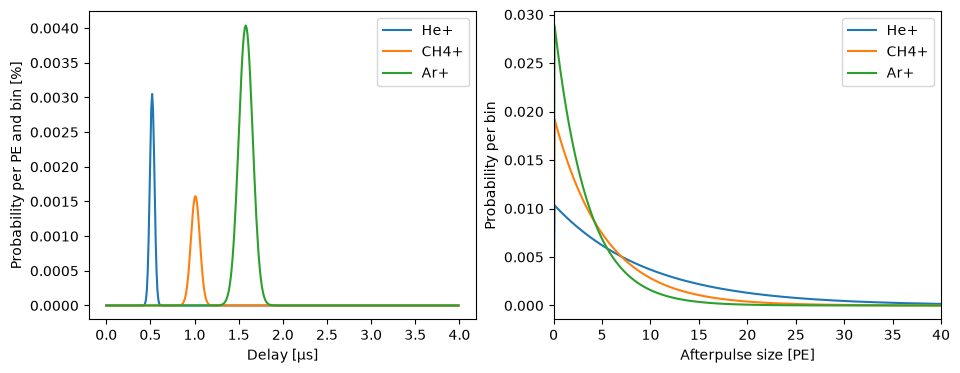

In [4]:
figure, (left, right) = plt.subplots(1, 2, figsize=(11, 4))

delay_values = np.arange(n_delay_bins) * delaytime_bin_size
amplitude_values = np.arange(n_amplitude_bins) * amplitude_bin_size
for name, entry in afterpulse_config.items():
    delay_probabilities = np.diff(entry["delaytime_cdf"][0], prepend=0)
    left.plot(delay_values / 1000, 100 * delay_probabilities, label=name)
    size_probabilities = np.diff(entry["amplitude_cdf"], prepend=0)
    right.plot(amplitude_values, size_probabilities, label=name)

left.set_xlabel("Delay [µs]")
left.set_ylabel("Probability per PE and bin [%]")
left.legend()
right.set_xlabel("Afterpulse size [PE]")
right.set_ylabel("Probability per bin")
right.set_xlim(0, 40)
right.legend()
plt.show()

In [5]:
output_file = DUMMY_MAP_DIRECTORY / "pmt_afterpulse_config_dummy.json.gz"
serializable_config = {
    name: {key: value.tolist() if isinstance(value, np.ndarray) else value for key, value in entry.items()}
    for name, entry in afterpulse_config.items()
}
with gzip.open(output_file, "wt") as json_file:
    json.dump(serializable_config, json_file)
print("Saved", output_file, f"({output_file.stat().st_size / 1e6:.2f} MB)")

Saved /mnt/d/XLZD/mymodules/ember/ember/dummy_maps/pmt_afterpulse_config_dummy.json.gz (0.09 MB)
